# Compare Rust 2D horizontal mapping with RAS Mapper

Generate native **horizontal** depth/WSE stored maps and compare them with the Rust 2D cell mapper, using the same optional strict `depth > min_depth` pixel filter. The default comparison threshold is 0.5 in model elevation units: half a foot only for feet-based models. `min_depth=0.0` retains positive depths without the half-foot cutoff. Both depth and WSE are masked.

The library rejects source models with **1D river centerlines/reaches or cross sections**, including mixed 1D/2D models. Coupled pipes/conduits are permitted; this mapper produces the 2D surface only. Computed cell WSE reflects the hydraulic model's structures; the mapper does not solve bridge, culvert or pipe hydraulics.

Use two large eBFE cases plus the public Bald Eagle dam/levee and bridge variants, Davis pipes/conduits. Dedicated culvert qualification is omitted. Provide completed results and stage every referenced dependency first. Native mapping can take minutes and write large products; this notebook does not run the solver. Full-domain cases can require tens of GB of RAM. Use C: NVMe for the primary comparison on Windows when available, and archive completed data separately.

The comparison API owns native execution, independent thresholding, runtime/performance records and byte-for-byte `.rasmap` restoration. Agreement is qualified only for the selected horizontal 2D surfaces, profiles, terrain and cutoff; it does not establish universal RAS Mapper or sloping/1D renderer equivalence.


Saved outputs are authentic retained executions: the four baseline code cells ran together on five models; the additional cutoff-proof cell ran separately against the unchanged Davis baseline, after reloading setup/configuration and verifying the source HDF hash. Repeated execution counts reflect the separate kernel. The tables, logs and plots are retained without editing their output. Large model/raster files remain outside the repository.

## Install and prepare the fixtures

From this PR checkout, install `uv pip install -e ".[fim,compute]"`, the matching **0.3.0** Windows/Linux x86-64 engine wheel, `matplotlib`, and a notebook kernel using `uv` in a terminal. Native comparison needs an installed HEC-RAS mapping runtime (the retained runs use 7.0.1). The Rust engine rasterizes ownership/masks and reads terrain through terrio; Python writes GIS products.

| Fixture | Plan / mesh | Physical 2D cells | Geometry coverage |
|---|---|---:|---|
| eBFE Spring River | 02 / Spring | 422,715 | No river reaches, cross sections or SA/2D connections |
| eBFE Spring Creek | 01 / SPR_Mesh | 340,163 | No river reaches, cross sections or SA/2D connections |
| BaldEagleCrkMulti2D dam/levees | 02 / BaldEagleCr | 87,039 | Gated dam and three levee connections; no river reaches |
| BaldEagleCrkMulti2D bridges | 05 / BaldEagleCr | 24,718 | Seven bridge connections plus four other connections |
| Davis pipes/conduits | 02 / * | 2,716 | Two 2D areas, 132 conduits and 133 pipe nodes |

A `*` mesh selector includes every physical 2D mesh, assigning globally unique positional cell IDs. A single mesh retains its local HDF cell IDs. The eBFE retained results were computed by 6.1/5.0.7, and the retained public examples by 7.0; record the mapper runtime separately. Model elements are inspected below, rather than inferred from names.

Get the public examples with `RasExamples.extract_project`; the eBFE organizers are available through `RasExamples.organize_ebfe_model`. Public examples may require a separate `RasCmdr.compute_plan` run. No dedicated culvert fixture is qualified by this run. Muncie and the separate Bald Eagle Creek river example are rejection cases, not accepted fixtures.


In [1]:
from pathlib import Path
from datetime import datetime
import json
import logging
import os
import shutil
import sys

USE_LOCAL_SOURCE = False
if USE_LOCAL_SOURCE:
    repo_root = Path.cwd().resolve()
    if repo_root.name == "examples":
        repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root))

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from ras_commander import (RasExamples, RasFim, RasTerrain, GeomLateral,
                           HdfPipe, HdfStruc, StoreMapPerformanceOptions, init_ras_project)

WORK = Path(os.environ.get("RAS_COMMANDER_FIM_COMPARISON_ROOT", "working/fim-horizontal-comparison")).resolve()
WORK.mkdir(parents=True, exist_ok=True)
CONFIG = Path(os.environ.get("RAS_COMMANDER_FIM_CORPUS_CONFIG", WORK / "cases.json"))
RUN = WORK / "runs" / datetime.now().strftime("fim-%Y%m%d-%H%M%S")
RUN.mkdir(parents=True, exist_ok=False)
MAPPER_VERSION = "7.0.1"
MIN_DEPTH = 0.5                 # feet for these fixtures; not a unit conversion
THREADS = 4
WRITER_THREADS = 4
MAX_WORKING_MIB = 32768         # planned admission, not an RSS cap
ENGINE = os.environ.get("RAS_COMMANDER_FIM_HORIZONTAL_ENGINE")


## Configure computed, isolated projects

Create `cases.json` with the fixture entries. Each needs `model`, `project_file`, `plan`, `mesh` and registered `terrain`. `mesh="*"` maps both Davis areas. Paths resolve relative to the configuration file. Set `staged=true` only for writable copies inside `WORK`; otherwise the notebook copies the complete source project to a new folder after a 240-character path preflight.

Optional fields:
- `terrain_path`: exact registered terrain surface as a float32 GeoTIFF, including applied modifications. If omitted, export through native RAS Mapper before timing.
- `bbox`: optional AOI. Native still maps the whole plan, so the API withholds a speed ratio for this unmatched workload.
- `canonical_crs=true`: explicitly rewrite custom GeoTIFF CRS keys to an equivalent EPSG encoding. Required for the retained Davis HARN terrain with terrio 0.4.2. `RasFim.canonicalize_terrain_crs` verifies pixel bits and the grid, writes a receipt, and performs no reprojection/resampling. Preparation is outside mapping timing.
- `expected_bridge_connections`, `expected_culvert_groups`, `expected_pipe_conduits`: minimum compiled/inventory counts required for qualification.
- `native_workers`: native helper-process count; use 2 for Davis to isolate depth/WSE generation. Independent helpers require exactly one registered terrain. Aggregate StoreAllMaps intermittently produced incomplete Davis WSE in qualification; failed reference runs are excluded, not repaired with candidate values. The notebook raises on missing WSE.
- `fixture_note`: identify derived cases and their separate solver evidence.

Example entry:
```json
{"model":"Davis", "project_file":"prepared/Davis/DavisStormSystem.prj",
 "plan":"02", "mesh":"*", "terrain":"Terrain (1)",
 "canonical_crs":true, "expected_pipe_conduits":132, "native_workers":2}
```

Use full domains for comparable mapping workloads when memory permits. A selected mesh, AOI, caller-supplied partial cell table, or native storage-area surfaces outside the 2D cells is labelled in returned performance metadata. Timings are shared-workstation observations; source loading, terrain preparation, hashing and comparison are excluded from the mapping totals.


In [2]:
cases = json.loads(CONFIG.read_text(encoding="utf-8"))
assert len(cases) >= 3, "Include the large-model and structure fixtures"
for case in cases:
    source = Path(case["project_file"])
    if not source.is_absolute():
        source = CONFIG.parent / source
    source = source.resolve()
    if not source.is_file():
        raise FileNotFoundError(source)
    if case.get("staged", False):
        if not source.is_relative_to(WORK):
            raise ValueError("A staged project must be inside the isolated WORK folder")
        case["staged_project"] = source
    else:
        destination = RUN / "models" / case["model"].replace(" ", "_")
        longest = max(len(str(destination / p.relative_to(source.parent)))
                      for p in source.parent.rglob("*") if p.is_file())
        if longest > 240:
            raise ValueError("Choose a shorter configured WORK path before staging")
        shutil.copytree(source.parent, destination)
        case["staged_project"] = destination / source.name
pd.DataFrame([{k:c.get(k) for k in ("model", "plan", "mesh", "fixture_note")} for c in cases])


,model,plan,mesh,fixture_note
0,spring-river,02,Spring,None
1,spring-creek,01,SPR_Mesh,None
2,bald-eagle,02,BaldEagleCr,None
3,bald-bridges,05,BaldEagleCr,None
4,davis,02,*,None


## Map, compare and return performance

`compare_with_rasmapper` returns the comparison DataFrame plus `result.attrs["performance"]`, a dictionary of Rust batch, native stored-map, native filtered-delivery and comparison timings. The same fields are persisted in JSON; labelled timing columns are also in CSV. Shared Rust setup is timed once, and per-profile candidate time is NaN for a multi-profile batch. Native raw rasters stay unchanged. Set `postprocess_reference=False` to omit written native filtered products; the independent cutoff still applies to comparison metrics and the API withholds the delivery-time ratio.

The following block requires nonempty wet coverage, no wet-mask differences and exact finite depth/WSE values for each fixture. It verifies the restored configuration and inspects native compiled structure counts. It raises on an unmet criterion instead of silently skipping it. A failed/partial run does not qualify the corpus. The output table keeps full native generation and postprocessing time visible even when an AOI or storage-area scope prevents a meaningful ratio.


In [3]:
results, performance_rows, inventory_rows = [], [], []
for i, case in enumerate(cases):
    project = init_ras_project(case["staged_project"], MAPPER_VERSION, ras_object="new",
                               hide_intro=True, load_results_summary=False)
    mapping = project.rasmap_df.iloc[0]
    if mapping["rasmap_status"] not in ("parsed", "parsed_with_errors"):
        raise ValueError("The staged rasmap must parse successfully")
    for path in [mapping["projection_path"], *mapping["terrain_hdf_path"]]:
        resolved = Path(path).resolve()
        if not resolved.is_file() or not resolved.is_relative_to(project.project_folder.resolve()):
            raise ValueError("Stage all referenced projection and terrain files inside the project")
    row = project.plan_df.loc[project.plan_df["plan_number"] == case["plan"]].iloc[0]
    hdf_path = Path(str(row["full_path"]) + ".hdf")
    scope = RasFim.validate_2d_model(hdf_path, geom_path=row["Geom Path"])
    cells = RasFim.get_cells_from_plan_hdf(hdf_path, mesh_name=case["mesh"])
    connections = GeomLateral.get_connections(row["Geom Path"])
    compiled = HdfStruc.get_structures(hdf_path)
    bridges = int((connections["Conn Routing Type"] == 32).sum()) if len(connections) else 0
    culverts = int(compiled["Culvert Groups"].sum()) if "Culvert Groups" in compiled else 0
    pipes = len(HdfPipe.get_pipe_conduits(hdf_path)) if case.get("expected_pipe_conduits", 0) else 0
    assert bridges >= case.get("expected_bridge_connections", 0)
    assert culverts >= case.get("expected_culvert_groups", 0), "Culvert must exist in compiled native geometry"
    assert pipes >= case.get("expected_pipe_conduits", 0)
    inventory_rows.append(dict(model=case["model"], physical_cells=len(cells),
        meshes=", ".join(scope["mesh_names"]), connections=len(connections),
        bridge_connections=bridges, compiled_culvert_groups=culverts, pipe_conduits=pipes,
        river_reaches=scope["text_reaches"], cross_sections=scope["cross_section_records"]))
    out = RUN / f"{i:02d}"
    out.mkdir()
    if case.get("terrain_path"):
        terrain = Path(case["terrain_path"])
        if not terrain.is_absolute():
            terrain = CONFIG.parent / terrain
        terrain = terrain.resolve()
    else:
        terrain = out / "native-terrain.tif"
        extent = case.get("bbox", cells.total_bounds.tolist())
        exported = RasTerrain.export_rasmapper_terrain(
            project.project_folder, terrain, terrain_name=case["terrain"], extent=extent,
            rasterize_modifications=True, hecras_version=MAPPER_VERSION,
            ras_object=project, timeout_seconds=1800,
        )
        if not exported:
            raise RuntimeError(f"Native terrain export failed: {exported}")
    if case.get("canonical_crs", False):
        terrain = RasFim.canonicalize_terrain_crs(terrain, out / "canonical-terrain.tif")
    comparison = RasFim.compare_with_rasmapper(
        case["plan"], terrain, out / "comparison", mesh_name=case["mesh"],
        terrain_name=case["terrain"], bbox=case.get("bbox"), min_depth=MIN_DEPTH,
        engine_path=ENGINE, threads=THREADS, writer_threads=WRITER_THREADS,
        max_working_mib=MAX_WORKING_MIB, ras_object=project,
        native_performance=(StoreMapPerformanceOptions(max_workers=case["native_workers"])
                            if "native_workers" in case else None),
        ras_version=MAPPER_VERSION, timeout=1800,
    )
    assert comparison.attrs["rasmap_restored"]
    assert (comparison.common_wet > 0).all()
    assert (comparison.extra_wet == 0).all() and (comparison.missing_wet == 0).all()
    assert (comparison.depth_max_abs == 0).all() and (comparison.wse_max_abs == 0).all()
    assert (comparison.reference_missing_wse == 0).all() and (comparison.candidate_missing_wse == 0).all()
    perf = comparison.attrs["performance"]
    performance_rows.append(dict(model=case["model"], rust_seconds=perf["candidate_batch_seconds"],
        rasmapper_seconds=perf["native_store_maps_seconds"], native_filter_seconds=perf["native_postprocess_seconds"],
        native_total_seconds=perf["native_total_seconds"], comparison_seconds=perf["comparison_seconds"],
        observed_ratio=perf["observed_native_to_candidate_ratio"],
        ratio_note="; ".join(perf["ratio_exclusions"]),
        native_requested_workers=case.get("native_workers", 1)))
    comparison.insert(0, "model", case["model"])
    results.append(comparison)
    display(comparison[["model", "common_wet", "extra_wet", "missing_wet", "depth_max_abs", "wse_max_abs"]])
    del cells

summary = pd.concat(results, ignore_index=True)
inventory = pd.DataFrame(inventory_rows)
performance = pd.DataFrame(performance_rows)
summary.to_csv(RUN / "corpus-comparison.csv", index=False)
inventory.to_csv(RUN / "fixture-inventory.csv", index=False)
performance.to_csv(RUN / "corpus-performance.csv", index=False)
display(inventory)
display(performance.round(3))


2026-10-25 11:28:43 - ras_commander.hdf.HdfResultsMesh - INFO - Maximum-depth source for mesh 'Spring' in 'Spring_BLE.p02.hdf': derived in memory by ras-commander from HEC-RAS HDF 'Water Surface' minus 'Cells Minimum Elevation'; no 'Depth' dataset was created or written.


2026-10-25 11:28:50 - ras_commander.hdf.HdfResultsMesh - INFO - Maximum-depth source for mesh 'Spring' in 'Spring_BLE.p02.hdf': derived in memory by ras-commander from HEC-RAS HDF 'Water Surface' minus 'Cells Minimum Elevation'; no 'Depth' dataset was created or written.


2026-10-25 11:29:58 - ras_commander.RasMap - INFO - Set water surface render mode to 'horizontal'


2026-10-25 11:35:12 - ras_commander.RasProcess - INFO - StoreAllMaps complete: plan=02; mode=horizontal; map_types=2; files=2


,model,common_wet,extra_wet,missing_wet,depth_max_abs,wse_max_abs
0,spring-river,35270078,0,0,0.0,0.0


...

2026-10-25 11:45:56 - ras_commander.RasProcess - INFO - Generating 2 stored-map types with 2 helper processes


2026-10-25 11:45:58 - ras_commander.RasProcess - INFO - Parallel StoreMap complete: plan=02; mode=horizontal; map_types=2; files=2


,model,common_wet,extra_wet,missing_wet,depth_max_abs,wse_max_abs
0,davis,4883,0,0,0.0,0.0


,model,physical_cells,meshes,connections,bridge_connections,compiled_culvert_groups,pipe_conduits,river_reaches,cross_sections
0,spring-river,422715,Spring,0,0,0,0,0,0
1,spring-creek,340163,SPR_Mesh,0,0,0,0,0,0
2,bald-eagle,87039,BaldEagleCr,4,0,0,0,0,0
3,bald-bridges,24718,BaldEagleCr,11,7,0,0,0,0
4,davis,2716,"DS Channel, area2",0,0,0,132,0,0


,model,rust_seconds,rasmapper_seconds,native_filter_seconds,native_total_seconds,comparison_seconds,observed_ratio,ratio_note,native_requested_workers
0,spring-river,60.865,313.980,30.824,344.805,105.731,5.665,,1
1,spring-creek,55.545,266.934,23.681,290.615,88.986,5.232,,1
2,bald-eagle,6.108,8.059,2.109,10.169,5.384,NaN,Native mapping may include storage-area surfac...,1
3,bald-bridges,3.142,7.596,1.027,8.624,4.466,2.744,,1
4,davis,0.257,1.700,0.024,1.724,0.180,6.713,,2


## Inspect performance and spatial agreement

The chart separates native generation from independently filtered delivery writes. Rust's total includes its integrated filter and delivered GeoTIFFs. Times are observations in fixed Rust-first order on the active workstation, not a controlled population speedup. No ratio is promoted for unmatched scope. The final fixture supplies a spatial view of native depth, Rust depth and their difference on exactly matching grid pixels.

Keep authentic executed notebook output and JSON receipts with the run. Source models, native rasters, large arrays and local path-bearing evidence remain in the configured working folder rather than the source repository. The qualified source notebook calls the public API; it does not embed substitute mapping logic.


### Retained five-model execution

Windows x86-64, mapper 7.0.1 and engine 0.3.0, four allowed logical CPUs, one Max profile per model and strict depth > 0.5 ft. All evaluated wet masks and finite depth/WSE values matched; every native call restored its rasmap bytes. Times exclude input/terrain preparation and comparison scanning. They are single Rust-first shared-host observations. Native total includes independent filtered-delivery writing. Davis uses two independent native helpers; other cases use aggregate native generation.

| Fixture | Rust delivered (s) | Native delivered total (s) |
|---|---:|---:|
| spring-river | 60.865 | 344.805 |
| spring-creek | 55.545 | 290.615 |
| bald-eagle | 6.108 | 10.169 |
| bald-bridges | 3.142 | 8.624 |
| davis | 0.257 | 1.724 |


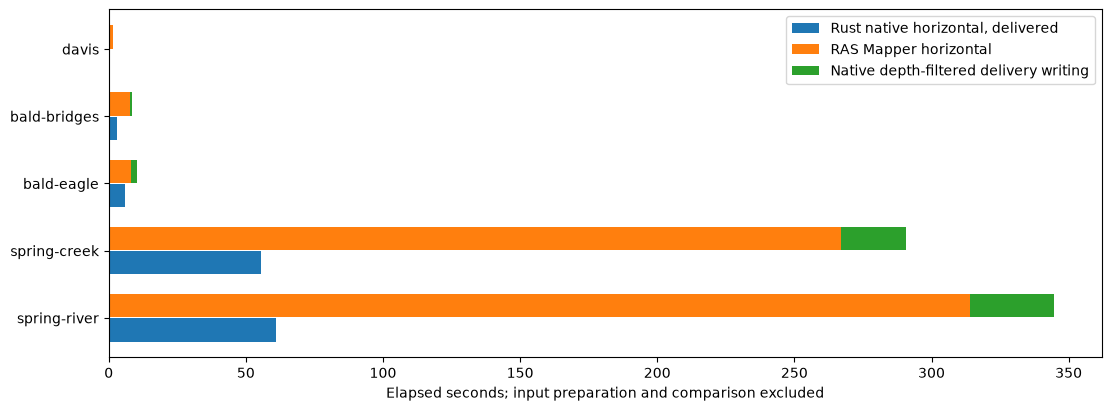

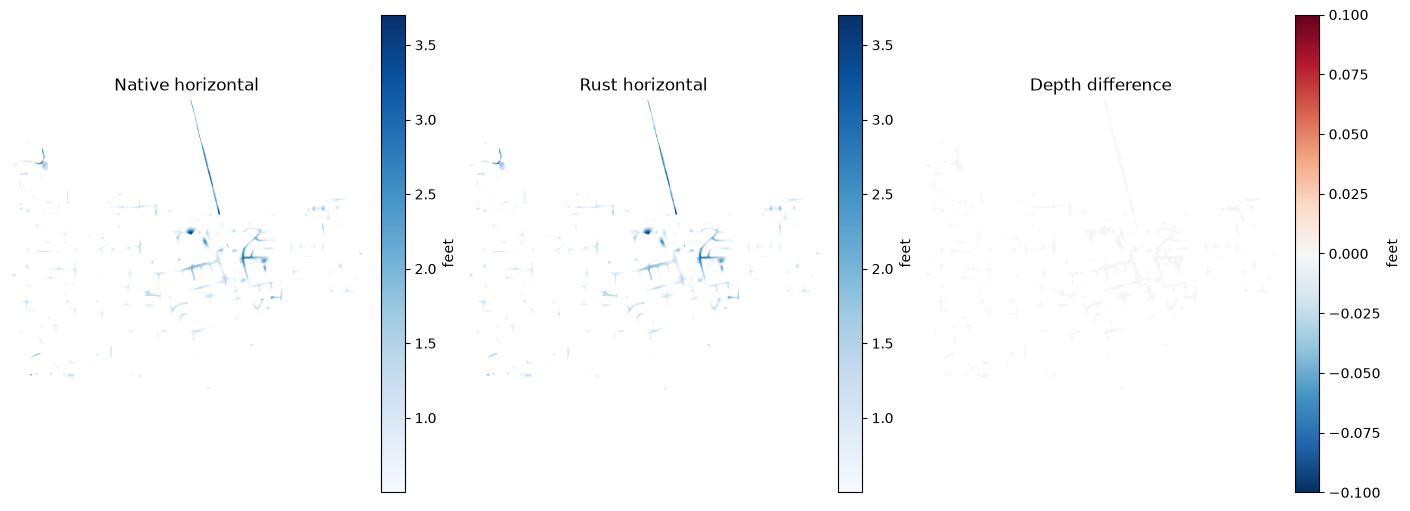

In [4]:
fig, ax = plt.subplots(figsize=(11, max(4, len(performance)*.7)), layout="constrained")
y = np.arange(len(performance))
ax.barh(y-.18, performance.rust_seconds, height=.35, label="Rust native horizontal, delivered")
ax.barh(y+.18, performance.rasmapper_seconds, height=.35, label="RAS Mapper horizontal")
ax.barh(y+.18, performance.native_filter_seconds, left=performance.rasmapper_seconds,
        height=.35, label="Native depth-filtered delivery writing")
ax.set_yticks(y, performance.model)
ax.set_xlabel("Elapsed seconds; input preparation and comparison excluded")
ax.legend()
plt.show()

from rasterio.windows import Window
row = summary.iloc[-1]
with rasterio.open(row["depth_tif"]) as candidate, rasterio.open(row["reference_depth_tif"]) as reference:
    a = candidate.read(1, masked=True).filled(np.nan)
    col = round((candidate.transform.c-reference.transform.c)/reference.transform.a)
    line = round((candidate.transform.f-reference.transform.f)/reference.transform.e)
    b = reference.read(1, window=Window(col,line,candidate.width,candidate.height),
                       boundless=True, masked=True).astype("float32").filled(np.nan)
    a = np.where(a > np.float32(MIN_DEPTH), a, np.nan)
    b = np.where(b > np.float32(MIN_DEPTH), b, np.nan)
fig, axes = plt.subplots(1,3,figsize=(14,5),layout="constrained")
for axis,data,title in zip(axes,[b,a,a-b],["Native horizontal", "Rust horizontal", "Depth difference"]):
    image = axis.imshow(data, cmap="RdBu_r" if title=="Depth difference" else "Blues")
    axis.set_title(title);axis.set_axis_off()
    fig.colorbar(image,ax=axis,label="feet")
plt.show()


## Interpret timings and preserve evidence

`native_seconds` measures each native stored-map call. `rust_batch_seconds` measures the entire candidate batch, including preparation and GIS writing. These include different stages and are not a controlled speed ratio. For throughput measurements, stage identical inputs before timing, use equal CPU budgets, interleave repeated runs, retain warm-up/cache policy, and require numerical equality between Rust and the explicit NumPy reference.

Retain `comparison.json`, `comparison.csv`, the terrain export receipt and original raster products. The report binds the native runtime, terrain identity, threshold and restored `.rasmap` hashes. Do not commit model data or large generated rasters. Native horizontal construction follows the [HEC-RAS6.6 Mapping Options](https://www.hec.usace.army.mil/confluence/rasdocs/rmum/6.6/mapping-results/mapping-options); RAS Commander is an independent implementation, and these checks do not imply HEC endorsement.

## Prove varying pixel-depth postprocessing

Apply strict cutoffs of 0.0, 0.5, 1.0 and 2.0 in model elevation units (feet for these fixtures). The configured corpus places Davis last so this repeat is small. Reuse the last fixture's **raw, unfiltered native maps** from the completed baseline above; native mapping does not change with this postprocessing cutoff. Generate Rust delivery products at each cutoff and use the public `RasFim.compare_rasters` API to apply that cutoff independently during numerical comparison. Never use a reference already filtered at a higher cutoff.

The 0.5, 1.0 and 2.0 ft cutoffs must have exact depth/WSE and wet-mask agreement. The zero-cutoff row is diagnostic: Davis retained 50 additional Rust pixels with positive depths from 0.00005340576 to 0.0009918213 ft, while all common-wet depth/WSE values matched. Its wet mask is not qualified as exact. No native near-zero suppression rule is inferred or silently added. Both Rust delivery bands must share the retained depth mask, and wet coverage must decrease or stay constant as the cutoff increases. No native data are repaired or substituted. This is a separately executed postprocessing proof, not a repeat of the baseline native-generation timing benchmark.

### Retained cutoff results

The additional fifth code cell was executed separately against the completed Davis native baseline. No native export was repeated for these results. The zero-cutoff row is not an exact wet-mask qualification.

| Cutoff (ft), strict > | Rust wet pixels | Native wet pixels | Extra / missing Rust wet pixels | Max depth / WSE difference (ft), common wet |
|---|---:|---:|---:|---:|
| 0 | 20,610 | 20,560 | 50 / 0 | 0 / 0 |
| 0.5 | 4,883 | 4,883 | 0 / 0 | 0 / 0 |
| 1 | 1,607 | 1,607 | 0 / 0 | 0 / 0 |
| 2 | 268 | 268 | 0 / 0 | 0 / 0 |


2026-10-25 12:00:20 - ras_commander.hdf.HdfResultsMesh - INFO - Maximum-depth source for mesh 'area2' in 'DavisStormSystem.p02.hdf': derived in memory by ras-commander from HEC-RAS HDF 'Water Surface' minus 'Cells Minimum Elevation'; no 'Depth' dataset was created or written.


2026-10-25 12:00:20 - ras_commander.hdf.HdfResultsMesh - INFO - Maximum-depth source for mesh 'DS Channel' in 'DavisStormSystem.p02.hdf': derived in memory by ras-commander from HEC-RAS HDF 'Water Surface' minus 'Cells Minimum Elevation'; no 'Depth' dataset was created or written.


,model,min_depth,candidate_wet,reference_wet,common_wet,extra_wet,missing_wet,depth_max_abs,wse_max_abs,exact_wet_mask
0,davis,0.0,20610,20560,20560,50,0,0.0,0.0,False
1,davis,0.5,4883,4883,4883,0,0,0.0,0.0,True
2,davis,1.0,1607,1607,1607,0,0,0.0,0.0,True
3,davis,2.0,268,268,268,0,0,0.0,0.0,True


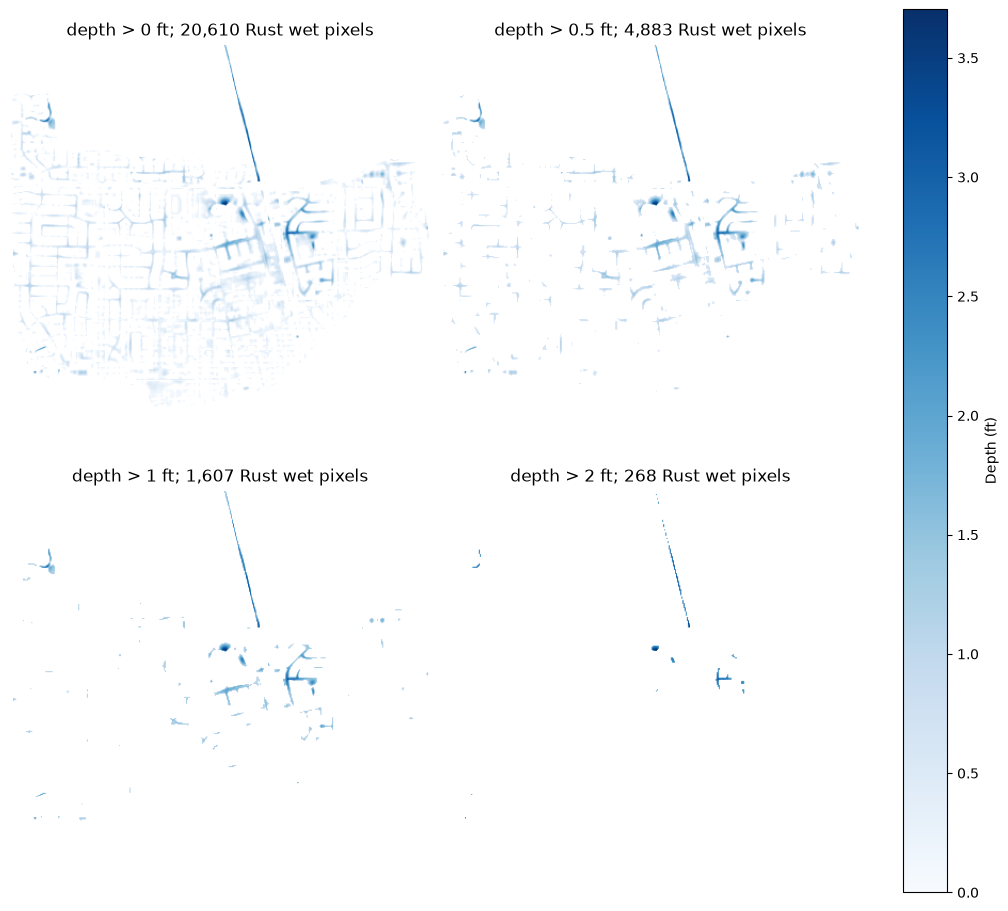

In [4]:
filter_case = cases[-1]
reference_row = summary.iloc[-1]
assert reference_row.model == filter_case["model"]
filter_project = init_ras_project(filter_case["staged_project"], MAPPER_VERSION,
    ras_object="new", hide_intro=True, load_results_summary=False)
filter_row = filter_project.plan_df.loc[
    filter_project.plan_df.plan_number == filter_case["plan"]].iloc[0]
filter_hdf = Path(str(filter_row["full_path"]) + ".hdf")
filter_cells = RasFim.get_cells_from_plan_hdf(filter_hdf, mesh_name=filter_case["mesh"])
filter_root = RUN / "varying-depth-filter"
filter_root.mkdir()
if filter_case.get("terrain_path"):
    filter_terrain = Path(filter_case["terrain_path"])
    if not filter_terrain.is_absolute():
        filter_terrain = CONFIG.parent / filter_terrain
else:
    filter_terrain = filter_root / "native-terrain.tif"
    exported = RasTerrain.export_rasmapper_terrain(
        filter_project.project_folder, filter_terrain,
        terrain_name=filter_case["terrain"], extent=filter_cells.total_bounds.tolist(),
        rasterize_modifications=True, hecras_version=MAPPER_VERSION,
        ras_object=filter_project, timeout_seconds=1800)
    if not exported:
        raise RuntimeError(f"Native terrain export failed: {exported}")
if filter_case.get("canonical_crs", False):
    filter_terrain = RasFim.canonicalize_terrain_crs(
        filter_terrain, filter_root / "canonical-terrain.tif")
filter_rows, filtered_depths = [], []
for cutoff in (0.0, 0.5, 1.0, 2.0):
    delivered = RasFim.map_horizontal_profiles(
        filter_cells, filter_terrain, filter_root / f"cutoff-{cutoff:g}",
        min_depth=cutoff, engine_path=ENGINE, threads=THREADS,
        writer_threads=WRITER_THREADS, max_working_mib=MAX_WORKING_MIB,
        write_floodplain=False)
    product = delivered.iloc[0]
    metrics = RasFim.compare_rasters(
        product.depth_tif, product.wse_tif,
        reference_row.reference_depth_tif, reference_row.reference_wse_tif,
        cells=filter_cells, min_depth=cutoff, terrain_path=filter_terrain)
    row = pd.Series(metrics)
    assert row.common_wet > 0
    if cutoff in (0.5, 1.0, 2.0):
        assert row.extra_wet == row.missing_wet == 0
    assert row.depth_max_abs == row.wse_max_abs == 0
    assert row.reference_missing_wse == row.candidate_missing_wse == 0
    with rasterio.open(product.depth_tif) as d, rasterio.open(product.wse_tif) as w:
        depth, wse = d.read(1, masked=True).filled(np.nan), w.read(1, masked=True).filled(np.nan)
        wet = np.isfinite(depth)
        assert np.array_equal(wet, np.isfinite(wse))
        assert (depth[wet] > np.float32(cutoff)).all()
        filtered_depths.append(depth)
    filter_rows.append(dict(model=filter_case["model"], min_depth=cutoff,
        candidate_wet=int(row.candidate_wet), reference_wet=int(row.reference_wet),
        common_wet=int(row.common_wet), extra_wet=int(row.extra_wet), missing_wet=int(row.missing_wet),
        depth_max_abs=row.depth_max_abs, wse_max_abs=row.wse_max_abs,
        exact_wet_mask=(row.extra_wet == row.missing_wet == 0)))
filter_summary = pd.DataFrame(filter_rows)
assert (filter_summary.candidate_wet.diff().dropna() <= 0).all()
assert (filter_summary.reference_wet.diff().dropna() <= 0).all()
filter_summary.to_csv(filter_root / "filter-comparison.csv", index=False)
display(filter_summary)
fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for axis, depth, row in zip(axes.flat, filtered_depths, filter_summary.itertuples()):
    image = axis.imshow(depth, cmap="Blues", vmin=0, vmax=np.nanmax(filtered_depths[0]))
    axis.set_title(f"depth > {row.min_depth:g} ft; {row.candidate_wet:,} Rust wet pixels")
    axis.set_axis_off()
fig.colorbar(image, ax=axes, label="Depth (ft)")
plt.show()


## Next roadmap item: native sloping interpolation

The next phase targets Rust parity with native RAS Mapper **sloping** interpolation and comparable measured throughput gains. It needs its own executable proof on identical terrain/grids/saved states, varying pixel-depth cutoffs, structures/barriers, wet-mask and depth/WSE metrics, and equal CPU budgets for single maps and timestep batches. Sloping support is future work; this PR completes the horizontal method and its proof.